#CALIFORNIA HOUSING DATASET

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score,accuracy_score

In [ ]:
data=fetch_california_housing(as_frame=True)

In [ ]:
features=data.data

In [ ]:
y=data.target

In [ ]:
x=features['AveRooms']

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=33)

In [ ]:
#Implementing linear regression using gradient descent
m,c=0,0
learning_rate=0.001
n=len(x_train)

for i in range(1000):
  y_pred=m*x_train+c
  dm=np.mean((y_pred-y_train)*x_train)
  dc=np.mean((y_pred-y_train))
  m=m-learning_rate*dm
  c=c-learning_rate*dc
y_pred_gd=x_test*m+c
print("------------Gradient Descent---------")
print(m,c)
print(f"Mean Squared Error:{mean_squared_error(y_test,y_pred_gd):.2f}")
print(f"R Squared:{r2_score(y_test,y_pred_gd):.2f}")


------------Gradient Descent---------
0.27768746820752266 0.3153229890734041
Mean Squared Error:1.56
R Squared:-0.16


In [ ]:
# Implementing linear regressionn using normal equation
x_train_new=np.c_[np.ones((n,1)),x_train]
theta=np.linalg.inv(x_train_new.T@x_train_new)@x_train_new.T@y_train
m=theta[1]
c=theta[0]
y_pred_ne=x_test*m+c
print("------------Normal Equation---------")
print(m,c)
print(f"Mean Squared Error:{mean_squared_error(y_test,y_pred_ne):.2f}")
print(f"R Squared:{r2_score(y_test,y_pred_ne):.2f}")

------------Normal Equation---------
0.06688885713892975 1.7021722888860071
Mean Squared Error:1.32
R Squared:0.03


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train.values.reshape(-1,1))
x_test_scaled=scaler.transform(x_test.values.reshape(-1,1))

#Implementing linear regression using gradient descent on scaled features
m,c=0,0
learning_rate=0.001
n=len(x_train_scaled)

for i in range(1000):
  y_pred=m*x_train_scaled.ravel()+c
  dm=np.mean((y_pred-y_train.to_numpy())*x_train_scaled.ravel())
  dc=np.mean((y_pred-y_train))
  m=m-learning_rate*dm
  c=c-learning_rate*dc
y_pred_gd=x_test_scaled*m+c
print("------------Gradient Descent---------")
print(m,c)
print(f"Mean Squared Error:{mean_squared_error(y_test,y_pred_gd):.2f}")
print(f"R Squared:{r2_score(y_test,y_pred_gd):.2f}")

------------Gradient Descent---------
0.10744580251979462 1.3055661091007111
Mean Squared Error:1.92
R Squared:-0.42


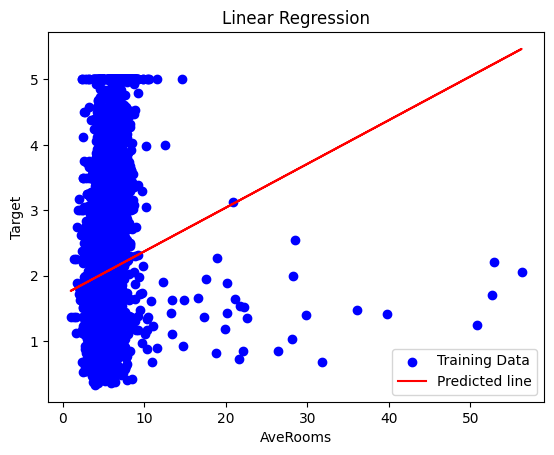

In [ ]:
plt.scatter(x_test,y_test,label="Training Data",color='blue')
plt.plot(x_test,y_pred_ne,color='red',label='Predicted line')
plt.legend()
plt.xlabel('AveRooms')
plt.ylabel('Target')
plt.title('Linear Regression')
plt.show()


In [ ]:
x.shape

(20640,)

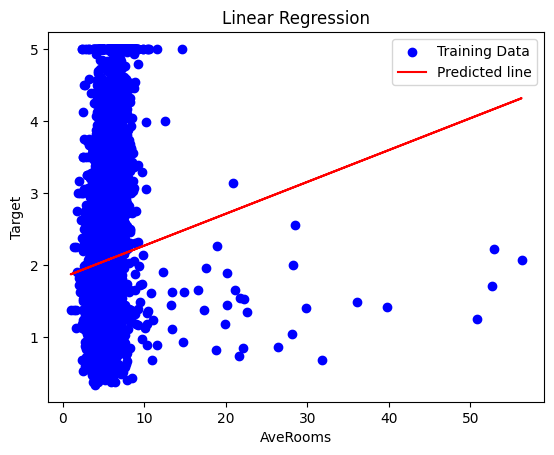

In [ ]:
from sklearn.linear_model import SGDRegressor
model=SGDRegressor(random_state=33)
model.fit(x_train_scaled,y_train)
y_pred_sgd=model.predict(x_test_scaled)
plt.scatter(x_test,y_test,label="Training Data",color='blue')
plt.plot(x_test,y_pred_sgd,color='red',label='Predicted line')
plt.legend()
plt.xlabel('AveRooms')
plt.ylabel('Target')
plt.title('Linear Regression')
plt.show()

#RIDGE AND LASSO

In [ ]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression,RidgeCV ,LassoCV
from sklearn.preprocessing import StandardScaler

In [ ]:
x,y=load_diabetes(return_X_y=True)

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=33)
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)
linear_model=LinearRegression()
ridge=RidgeCV(alphas=(np.logspace(-3,3,100)))
lasso=LassoCV(cv=5)

In [ ]:
models={'Linear':linear_model,'Ridge':ridge,'Lasso':lasso}
for name,model in models.items():
  model.fit(x_train_scaled,y_train)
  y_pred=model.predict(x_test_scaled)
  print(f"------------------{name}-----------------------------")
  print(f"{name} Mean Squared Error:{mean_squared_error(y_test,y_pred):.2f}")
  print(f"{name} R Squared:{r2_score(y_test,y_pred):.2f}")

------------------Linear-----------------------------
Linear Mean Squared Error:2777.10
Linear R Squared:0.48
------------------Ridge-----------------------------
Ridge Mean Squared Error:2766.15
Ridge R Squared:0.49
------------------Lasso-----------------------------
Lasso Mean Squared Error:2753.13
Lasso R Squared:0.49


In [ ]:
ridge.alpha_

np.float64(0.1519911082952933)

In [ ]:
x.shape

(442, 10)

In [ ]:
y.shape

(442,)

In [ ]:
from sklearn.linear_model import ElasticNetCV
elastic=ElasticNetCV(cv=5)
elastic.fit(x_train_scaled,y_train)
y_pred=model.predict(x_test_scaled)
print(f"------------------Elastic Net-----------------------------")
print(f"Elastic Net Mean Squared Error:{mean_squared_error(y_test,y_pred):.2f}")
print(f"Elastic Net R Squared:{r2_score(y_test,y_pred):.2f}")

------------------Elastic Net-----------------------------
Elastic Net Mean Squared Error:2753.13
Elastic Net R Squared:0.49


In [ ]:
from sklearn.svm import SVR
svr_linear=SVR(kernel='linear')
svr_rbf=SVR(kernel='rbf')
y_pred_linear=svr_linear.fit(x_train_scaled,y_train).predict(x_test_scaled)
y_pred_rbf=svr_rbf.fit(x_train_scaled,y_train).predict(x_test_scaled)
print(f"------------------SVR Linear-----------------------------")
print(f"SVR Linear Mean Squared Error:{mean_squared_error(y_test,y_pred_linear):.2f}")
print(f"SVR Linear R Squared:{r2_score(y_test,y_pred_linear):.2f}")
print(f"------------------SVR RBF-----------------------------")
print(f"SVR RBF Mean Squared Error:{mean_squared_error(y_test,y_pred_rbf):.2f}")
print(f"SVR RBF R Squared:{r2_score(y_test,y_pred_rbf):.2f}")

------------------SVR Linear-----------------------------
SVR Linear Mean Squared Error:2603.08
SVR Linear R Squared:0.52
------------------SVR RBF-----------------------------
SVR RBF Mean Squared Error:4348.72
SVR RBF R Squared:0.19


# **NAIVE BAYES**

In [ ]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB,BernoulliNB
from sklearn.metrics import accuracy_score,f1_score

In [ ]:
train=fetch_20newsgroups(subset='train',categories=['sci.space','rec.autos'])

In [ ]:
test=fetch_20newsgroups(subset='test',categories=['sci.space','rec.autos'])

In [ ]:
vec_multi=CountVectorizer()
x_train_multi=vec_multi.fit_transform(train.data)
x_test_multi=vec_multi.transform(test.data)

vec_ber=CountVectorizer(binary=True)
x_train_ber=vec_ber.fit_transform(train.data)
x_test_ber=vec_ber.transform(test.data)

model_multi=MultinomialNB().fit(x_train_multi,train.target)
model_ber=BernoulliNB().fit(x_train_ber,train.target)

y_pred_multi=model_multi.predict(x_test_multi)
y_pred_ber=model_ber.predict(x_test_ber)

print("----------MultinomialNB----------------")
print(f"Accuracy :{accuracy_score(test.target,y_pred_multi):.2f}")
print(f"F1 Score :{f1_score(test.target,y_pred_multi):.2f}")

print("----------BernoulliNB----------------")
print(f"Accuracy :{accuracy_score(test.target,y_pred_ber):.2f}")
print(f"F1 Score :{f1_score(test.target,y_pred_ber):.2f}")

----------MultinomialNB----------------
Accuracy :0.99
F1 Score :0.99
----------BernoulliNB----------------
Accuracy :0.93
F1 Score :0.92


#**KNN**

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from tensorflow.keras.datasets import fashion_mnist

In [ ]:
(x_train,y_train),(x_test,y_test)=fashion_mnist.load_data()


In [ ]:
x_train=x_train[:5000].reshape(5000,-1)/255
x_test=x_test[:1000].reshape(1000,-1)/255
y_train=y_train[:5000]
y_test=y_test[:1000]

In [ ]:
for k in range(1,15,1):
  knn=KNeighborsClassifier(n_neighbors=k)
  knn.fit(x_train,y_train)
  pred=knn.predict(x_test)
  print(f"K={k} f1 Score:{f1_score(y_test,pred,average='macro'):.2f}")


K=1 f1 Score:0.81
K=2 f1 Score:0.81
K=3 f1 Score:0.82
K=4 f1 Score:0.81
K=5 f1 Score:0.81
K=6 f1 Score:0.81
K=7 f1 Score:0.82
K=8 f1 Score:0.81
K=9 f1 Score:0.81
K=10 f1 Score:0.81
K=11 f1 Score:0.82
K=12 f1 Score:0.82
K=13 f1 Score:0.82
K=14 f1 Score:0.82


In [ ]:
x_train.shape

(5000, 784)

#**ID3**

In [ ]:
from sklearn.tree import DecisionTreeClassifier,plot_tree


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rohit8527kmr7518/online-retail-customer-classification-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'online-retail-customer-classification-dataset' dataset.
Path to dataset files: /kaggle/input/online-retail-customer-classification-dataset


In [ ]:
import os
path='/root/.cache/kagglehub/datasets/rohit8527kmr7518/online-retail-customer-classification-dataset/versions/3'

print(os.listdir(path))

['retail_customer_segmentation.csv']


In [ ]:
data=pd.read_csv(path+'/retail_customer_segmentation.csv')

In [ ]:
data.columns

Index(['customer_id', 'age', 'annual_income', 'months_active',
       'avg_monthly_spend', 'purchase_frequency', 'avg_order_value',
       'discount_usage_rate', 'return_rate', 'browsing_time_minutes',
       'support_interactions', 'payment_method', 'region', 'customer_segment'],
      dtype='object')

In [ ]:
data=pd.DataFrame(data)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id            50000 non-null  int64  
 1   age                    50000 non-null  int64  
 2   annual_income          46925 non-null  float64
 3   months_active          50000 non-null  int64  
 4   avg_monthly_spend      47480 non-null  float64
 5   purchase_frequency     48021 non-null  float64
 6   avg_order_value        50000 non-null  float64
 7   discount_usage_rate    47451 non-null  float64
 8   return_rate            47513 non-null  float64
 9   browsing_time_minutes  46066 non-null  float64
 10  support_interactions   48012 non-null  float64
 11  payment_method         50000 non-null  object 
 12  region                 50000 non-null  object 
 13  customer_segment       50000 non-null  object 
dtypes: float64(8), int64(3), object(3)
memory usage: 5.3+ 

In [ ]:
x=data.drop(['customer_id','customer_segment'],axis=1)
y=data['customer_segment']
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

# 1. Handle missing values for numerical columns (fill with median)
num_cols = x.select_dtypes(include=['int64', 'float64']).columns
imputer = SimpleImputer(strategy='median')
x[num_cols] = imputer.fit_transform(x[num_cols])

# 2. Encode categorical columns (payment_method and region) into numbers
x = pd.get_dummies(x, columns=['payment_method', 'region'], drop_first=True)

# 3. Split into Train and Test sets (80% training, 20% testing)

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2,random_state=33)

In [ ]:
id3=DecisionTreeClassifier(
    criterion='entropy',
    max_depth=3

)

In [ ]:
id3.fit(x_train,y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=3)

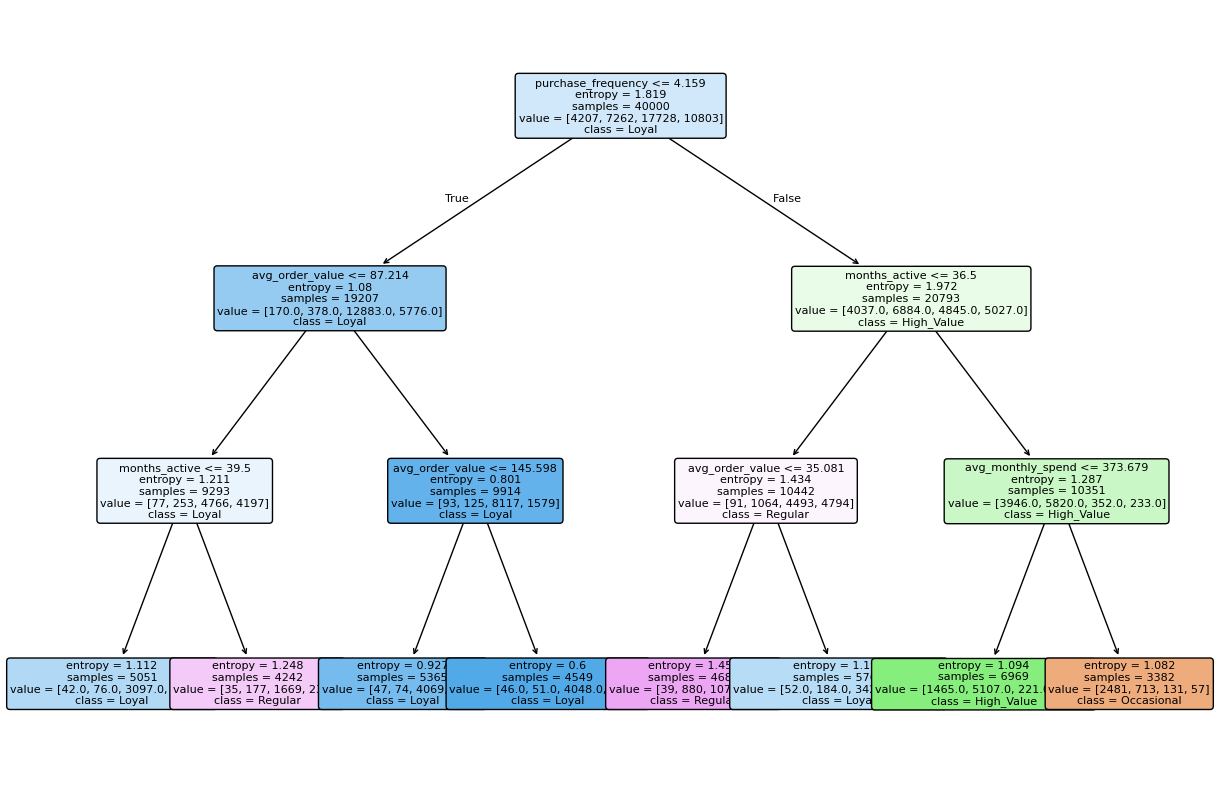

In [ ]:
plt.figure(figsize=(15,10))
plot_tree(id3,
          filled=True,
          feature_names=x.columns,
          class_names=y.unique().astype(str),
          rounded=True,
          fontsize=8
          )

plt.show()

In [ ]:
print("Feature Importance:",
      dict(zip(x.columns,id3.feature_importances_)))

Feature Importance: {'age': np.float64(0.0), 'annual_income': np.float64(0.0), 'months_active': np.float64(0.44764567313733855), 'avg_monthly_spend': np.float64(0.06983086459096162), 'purchase_frequency': np.float64(0.3780130090383391), 'avg_order_value': np.float64(0.10451045323336071), 'discount_usage_rate': np.float64(0.0), 'return_rate': np.float64(0.0), 'browsing_time_minutes': np.float64(0.0), 'support_interactions': np.float64(0.0), 'payment_method_UPI': np.float64(0.0), 'payment_method_Wallet': np.float64(0.0), 'region_Semi-Urban': np.float64(0.0), 'region_Urban': np.float64(0.0)}


#**SVM**

In [ ]:
from sklearn.datasets import load_iris
from sklearn.svm import SVC
from sklearn.metrics import classification_report

In [ ]:
data=load_iris(as_frame=True)

In [ ]:
x=data.data.drop(data.data.columns[2:],axis=1)
x=x.iloc[:100,:]

In [ ]:
y=data.target.iloc[:100]

In [ ]:
y.unique()

array([0, 1])

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2,random_state=33)
svm=SVC(kernel='linear')
svm.fit(x_train,y_train)
y_pred=svm.predict(x_test)
print(f"Accuracy:{(accuracy_score(y_test,y_pred)*100):.2f}%")
print(classification_report(y_test,y_pred))

Accuracy:95.00%
              precision    recall  f1-score   support

           0       1.00      0.83      0.91         6
           1       0.93      1.00      0.97        14

    accuracy                           0.95        20
   macro avg       0.97      0.92      0.94        20
weighted avg       0.95      0.95      0.95        20



In [ ]:
# Creating a meshgrid to reprsent like (x1,x2)
x_min,x_max=x.iloc[:,0].min()-1,x.iloc[:,0].max()+1
y_min,y_max=x.iloc[:,1].min()-1,x.iloc[:,1].max()+1
xx,yy=np.meshgrid(
    np.arange(x_min,x_max,0.02),
    np.arange(y_min,y_max,.02)
)
z=svm.predict(np.c_[xx.ravel(),yy.ravel()])
z=z.reshape(xx.shape)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


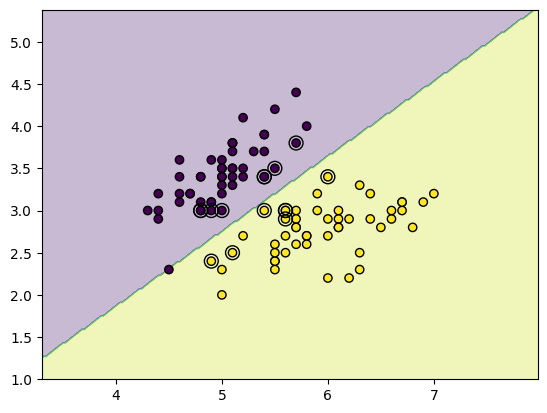

In [ ]:
plt.contourf(xx,yy,z,alpha=.3)
plt.scatter(x.iloc[:,0],x.iloc[:,1],c=y,edgecolor='k')
plt.scatter(
    svm.support_vectors_[:,0],
    svm.support_vectors_[:,1],
    s=100,
    linewidth=1,
    facecolors='none',
    edgecolors='k'
)

#**Bagging and Boosting**

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yasserh/titanic-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'titanic-dataset' dataset.
Path to dataset files: /kaggle/input/titanic-dataset


In [29]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier,AdaBoostClassifier


In [4]:
import os
print(os.listdir(path))

['Titanic-Dataset.csv']


In [5]:
data=pd.read_csv(path+'/Titanic-Dataset.csv')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
x=data[['Sex','Age','Fare','Pclass']]
y=data['Survived']

In [20]:
x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Sex     891 non-null    object 
 1   Age     891 non-null    float64
 2   Fare    891 non-null    float64
 3   Pclass  891 non-null    int64  
dtypes: float64(2), int64(1), object(1)
memory usage: 28.0+ KB


In [21]:
x['Age'].isnull().sum()

np.int64(0)

In [22]:
x['Age'].fillna(data['Age'].mean(),inplace=True)

/tmp/ipykernel_3084/4216624533.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x['Age'].fillna(data['Age'].mean(),inplace=True)


In [23]:
x['Sex']=x['Sex'].map({'male':0,'female':1})

/tmp/ipykernel_3084/1959331901.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x['Sex']=x['Sex'].map({'male':0,'female':1})


In [32]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=33)
bagging=BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    random_state=33
)
boosting=AdaBoostClassifier(
    n_estimators=100,
    random_state=33
)

bagging.fit(x_train,y_train)
boosting.fit(x_train,y_train)

y_pred_bagging=bagging.predict(x_test)
y_pred_boosting=boosting.predict(x_test)



In [33]:
from sklearn.metrics import f1_score,precision_score,recall_score
print(f"-----------Bagging----------------")
print(f"Bagging Accuracy:{accuracy_score(y_test,y_pred_bagging):.2f}")
print(f"Bagging F1 Score:{f1_score(y_test,y_pred_bagging):.2f}")
print(f"Bagging Precision Score:{precision_score(y_test,y_pred_bagging):.2f}")
print(f"Bagging Recall Score:{recall_score(y_test,y_pred_bagging):.2f}")
print(f"-----------AdaBoost----------------")
print(f"Boosting Accuracy:{accuracy_score(y_test,y_pred_boosting):.2f}")
print(f"Boosting F1 Score:{f1_score(y_test,y_pred_boosting):.2f}")
print(f"Boosting Precision Score:{precision_score(y_test,y_pred_boosting):.2f}")
print(f"Boosting Recall Score:{recall_score(y_test,y_pred_boosting):.2f}")
#

-----------Bagging----------------
Bagging Accuracy:0.82
Bagging F1 Score:0.76
Bagging Precision Score:0.82
Bagging Recall Score:0.71
-----------AdaBoost----------------
Boosting Accuracy:0.79
Boosting F1 Score:0.74
Boosting Precision Score:0.74
Boosting Recall Score:0.74


#**MLP**

In [35]:
from sklearn.datasets import fetch_openml

In [63]:
data=fetch_openml(name='wine-quality-red',version=1,as_frame=True)
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report

In [57]:

data.data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         1599 non-null   float64
 1   volatile_acidity      1599 non-null   float64
 2   citric_acid           1599 non-null   float64
 3   residual_sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free_sulfur_dioxide   1599 non-null   float64
 6   total_sulfur_dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
dtypes: float64(11)
memory usage: 137.5 KB


In [58]:
data.target.info()

<class 'pandas.core.series.Series'>
RangeIndex: 1599 entries, 0 to 1598
Series name: class
Non-Null Count  Dtype   
--------------  -----   
1599 non-null   category
dtypes: category(1)
memory usage: 1.9 KB


In [59]:
x=data.data

In [60]:
y=np.where(data.target.astype(int)>=6,1,0)

In [62]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=33)
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)


In [67]:
architecture=[(70,),(20,),(20,10),(89,25)]
for arch in architecture:
  print("Architecture :",arch)
  mlp=MLPClassifier(
      hidden_layer_sizes=arch,
      max_iter=2000,
      random_state=33
  )
  mlp.fit(x_train,y_train)
  y_pred=mlp.predict(x_test)
  print(f"Accuracy Score:{accuracy_score(y_test,y_pred):.2f}")
  print(classification_report(y_test,y_pred))

Architecture : (70,)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy Score:0.76
              precision    recall  f1-score   support

           0       0.75      0.73      0.74       150
           1       0.76      0.78      0.77       170

    accuracy                           0.76       320
   macro avg       0.76      0.75      0.75       320
weighted avg       0.76      0.76      0.76       320

Architecture : (20,)
Accuracy Score:0.72
              precision    recall  f1-score   support

           0       0.71      0.68      0.70       150
           1       0.73      0.76      0.74       170

    accuracy                           0.72       320
   macro avg       0.72      0.72      0.72       320
weighted avg       0.72      0.72      0.72       320

Architecture : (20, 10)
Accuracy Score:0.72
              precision    recall  f1-score   support

           0       0.71      0.71      0.71       150
           1       0.74      0.74      0.74       170

    accuracy                           0.72       320
   macro avg       0.72

#**PIMA INDIANS DIABETES DATASET**

In [71]:
from sklearn.linear_model import LogisticRegression


In [75]:
from sklearn.datasets import fetch_openml
data=fetch_openml(name='diabetes',version=1,as_frame=True)

In [76]:
data.data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   preg    768 non-null    int64  
 1   plas    768 non-null    int64  
 2   pres    768 non-null    int64  
 3   skin    768 non-null    int64  
 4   insu    768 non-null    int64  
 5   mass    768 non-null    float64
 6   pedi    768 non-null    float64
 7   age     768 non-null    int64  
dtypes: float64(2), int64(6)
memory usage: 48.1 KB


In [77]:
data.target.info()

<class 'pandas.core.series.Series'>
RangeIndex: 768 entries, 0 to 767
Series name: class
Non-Null Count  Dtype   
--------------  -----   
768 non-null    category
dtypes: category(1)
memory usage: 1.0 KB


In [78]:
x=data.data
y=data.target

In [79]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2,random_state=33)

In [83]:
x_test.shape ,y_test.shape

((154, 8), (154,))

In [90]:
model_raw=LogisticRegression(max_iter=1000)
model_raw.fit(x_train,y_train)
y_pred_raw=model_raw.predict(x_test)
print(f"Accuracy Score:{accuracy_score(y_test,y_pred_raw):.2f}")
print(classification_report(y_test,y_pred_raw))

Accuracy Score:0.73
                 precision    recall  f1-score   support

tested_negative       0.74      0.88      0.81        99
tested_positive       0.68      0.45      0.54        55

       accuracy                           0.73       154
      macro avg       0.71      0.67      0.67       154
   weighted avg       0.72      0.73      0.71       154



In [91]:
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)
model_scaled=LogisticRegression(max_iter=1000)
model_scaled.fit(x_train_scaled,y_train)
y_pred_scaled=model_scaled.predict(x_test_scaled)
print(f"Accuracy Score:{accuracy_score(y_test,y_pred_scaled):.2f}")
print(classification_report(y_test,y_pred_scaled))


Accuracy Score:0.73
                 precision    recall  f1-score   support

tested_negative       0.74      0.88      0.81        99
tested_positive       0.68      0.45      0.54        55

       accuracy                           0.73       154
      macro avg       0.71      0.67      0.67       154
   weighted avg       0.72      0.73      0.71       154



#**AUTO MPG**

In [92]:
data=fetch_openml(name='autoMpg',version=1,as_frame=True)

In [97]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression


In [95]:
data.data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   cylinders     398 non-null    category
 1   displacement  398 non-null    float64 
 2   horsepower    392 non-null    float64 
 3   weight        398 non-null    int64   
 4   acceleration  398 non-null    float64 
 5   model         398 non-null    category
 6   origin        398 non-null    category
dtypes: category(3), float64(3), int64(1)
memory usage: 14.7 KB


In [104]:
x=data.data[['displacement']]
y=data.target

In [119]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=33)
model=LinearRegression()
poly2=PolynomialFeatures(degree=2)
x_train_poly2=poly2.fit_transform(x_train)
x_test_poly2=poly2.transform(x_test)

poly3=PolynomialFeatures(degree=3)
x_train_poly3=poly3.fit_transform(x_train)
x_test_poly3=poly3.transform(x_test)

In [120]:
model.fit(x_train,y_train)
y_pred_lin=model.predict(x_test)
print("-----------Linear------------")
print(f"MSE:{mean_squared_error(y_test,y_pred_lin):.2f}")
print(f"R2 Score:{r2_score(y_test,y_pred_lin):.2f}")
model.fit(x_train_poly2,y_train)
y_pred_poly2=model.predict(x_test_poly2)
print("-----------Polynomial Degree 2------------")
print(f"MSE:{mean_squared_error(y_test,y_pred_poly2):.2f}")
print(f"R2 Score:{r2_score(y_test,y_pred_poly2):.2f}")
model.fit(x_train_poly3,y_train)
y_pred_poly3=model.predict(x_test_poly3)
print("-----------Polynomial Degree 3------------")
print(f"MSE:{mean_squared_error(y_test,y_pred_poly3):.2f}")
print(f"R2 Score:{r2_score(y_test,y_pred_poly3):.2f}")

-----------Linear------------
MSE:22.13
R2 Score:0.64
-----------Polynomial Degree 2------------
MSE:19.51
R2 Score:0.68
-----------Polynomial Degree 3------------
MSE:19.35
R2 Score:0.68


In [121]:
x_plot=np.linspace(x['displacement'].min(),x['displacement'].max(),100)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


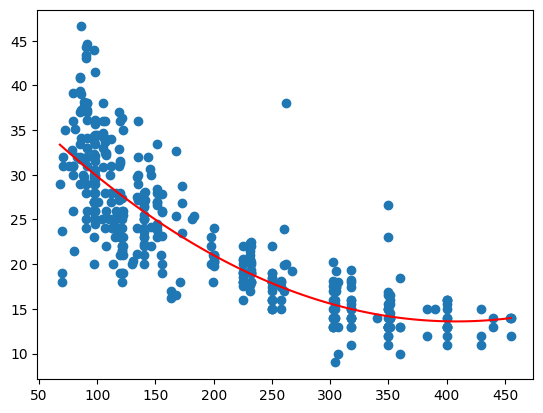

In [125]:
x_plot_poly2=poly2.transform(x_plot.reshape(-1,1))
model2=LinearRegression()
model2.fit(x_train_poly2,y_train)
y_plot_pred=model2.predict(x_plot_poly2)
plt.scatter(x['displacement'],y)
plt.plot(x_plot,y_plot_pred,color='red')
plt.show()

#**SPAM OR NOT SPAM**

In [126]:
data=fetch_openml(name='spambase',version=1,as_frame=True)


In [141]:
model=LogisticRegression(max_iter=5000)

In [137]:
x=data.data
y=data.target

In [142]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=33)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)
print(f"Accuracy Score:{accuracy_score(y_test,y_pred):.2f}")


Accuracy Score:0.95


In [161]:
new_spam=np.random.uniform(.001,100,55)

In [162]:
new_spam1=np.random.randint(1,100,2)

In [163]:
test_spam=np.concatenate([new_spam,new_spam1])

In [165]:
test_spam.shape

(57,)

In [170]:
test_spam.shape
new_pred=model.predict(test_spam.reshape(1,-1))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [171]:
if new_pred[0]==1:
  print("Spam")
else:
  print("Not Spam")

Not Spam


array(['0'], dtype=object)